# ANA675 Assignments & Projects
<a id="title"></a>

[Project Repo](https://github.com/Ethereal-Mining-Company/656D632D70726F6A2D32) \
Christopher Doupis \
December 6, 2026

<div class="alert alert-info" style="color: black;">
    
### AI USE DISCLAIMER & ACADEMIC INTEGRITY COMPLIANCE
In compliance with the [**National University Student Guidelines for Generative AI**](https://resources.nu.edu/ai/ai-guidelines), this project discloses the following tool usage:

* **Conceptual Framing & Brainstorming (AI-Informed):** **Google Gemini** was utilized as a supplemental learning resource to clarify core mathematical and analytical concepts across the assignment questions. 
* **Technical Execution & Boilerplate Generation (AI-Assisted):** **Google Gemini** was used to generate initial code structures and programming boilerplates. These templates were subsequently modified, debugged, and tailored to meet the specific requirements of each question.
* **Human Oversight, Validation Loops & Refinement (Author-Owned):** The author maintained complete conceptual control, process oversight, and ownership of the entire homework scope. All AI-assisted templates, code logic, and conceptual outputs were systematically reviewed and validated by the author to ensure academic accuracy and integrity.
* **Disclosure Statement (AI-Generated):** **Google Gemini** was utilized to structure and audit this text format to fulfill all institutional reporting standards.
</div>

### REFERENCES
#### Peer Reviewed and Scientific References

#### Generative AI & Software Tools
* **[Google.](https://google.com)** (2026). *Gemini* [Large language model]. https://google.com

# Handwritten Postal Digit Classification (Assignment Week 1)
**Goal:** Predict which digit (`0`–`9`) an 8×8 handwritten image represents by comparing `KNeighborsClassifier`, `SVC`, and `GaussianNB`.

## 1. Load and Explore the Data

Success! Exported 'load_digits' cleanly into 'data/digits_dataset.csv'
Dataset shape (rows, columns): (1797, 65)

Class distribution (digits 0-9):
target_digit
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


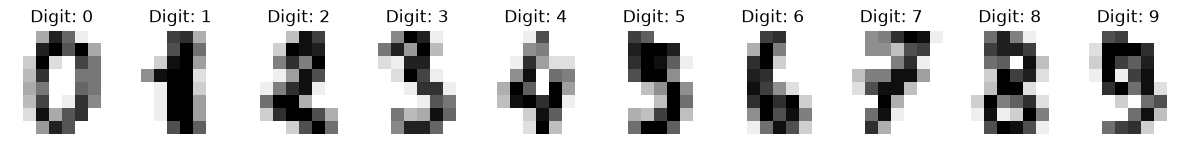

In [1]:
import os
import pandas as pd
from sklearn.metrics import classification_report
from src import pipeline, utils, visualization

config = utils.load_config()
target_col = config["features"]["target_col"]

dataset_path = utils.export_sklearn_dataset(
    loader_name="load_digits",
    target_file_name="digits_dataset.csv",
    target_col_name=target_col
)

df = pd.read_csv(dataset_path)
X_full = df.drop(columns=[target_col])
y_full = df[target_col]

print("Dataset shape (rows, columns):", df.shape)
print("\nClass distribution (digits 0-9):")
print(y_full.value_counts().sort_index())

visualization.plot_sample_digits(X_full, y_full, count=10)

## 2. Split the Data for Training and Testing (10 points)

In [2]:
X_train, X_test, y_train, y_test = pipeline.load_and_split_data(
    data_path=dataset_path,
    target_col=target_col,
    seed=config["evaluation_params"]["global_seed"],
    test_size=0.2
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")

Training samples: 1437
Testing samples:  360


## 3. Select and Build the Model (10 points)

In [3]:
for model_cfg in config["experiment_setup"]:
    built_model = pipeline.instantiate_model(
        module_path=model_cfg["module_path"],
        class_name=model_cfg["class_name"]
    )
    print(f"Configured '{model_cfg['name']}': {built_model}")

Configured 'knn': KNeighborsClassifier()
Configured 'svc': SVC()
Configured 'gnb': GaussianNB()


## 4. Train, Tune, and Run Several Classification Models
*Note: `pipeline.run_generalized_pipeline()` executes hyperparameter tuning via 5-fold cross-validation (`execute_kfold_tuning`), trains the winning model on the full training set (`best_engine.fit`), and logs all runs across `knn`, `svc`, and `gnb` in a single unified workflow.*


--- Running [PRODUCTION] Validation For: KNN (run_df47a718) ---
Source: data/digits_dataset.csv
Overrides applied: {'n_neighbors': [3, 5, 7]}
Success! Processed KNN

--- Running [PRODUCTION] Validation For: SVC (run_8601dabb) ---
Source: data/digits_dataset.csv
Overrides applied: {'C': [0.1, 1, 10], 'gamma': ['scale', 'auto']}
Success! Processed SVC

--- Running [PRODUCTION] Validation For: GNB (run_699576aa) ---
Source: data/digits_dataset.csv
Success! Processed GNB


,run_uuid,engine_type,test_mode,mean_cv_accuracy,final_test_score
0,run_8601dabb,svc,N,0.988161,0.994444
1,run_df47a718,knn,N,0.983984,0.986111
2,run_699576aa,gnb,N,0.824610,0.811111


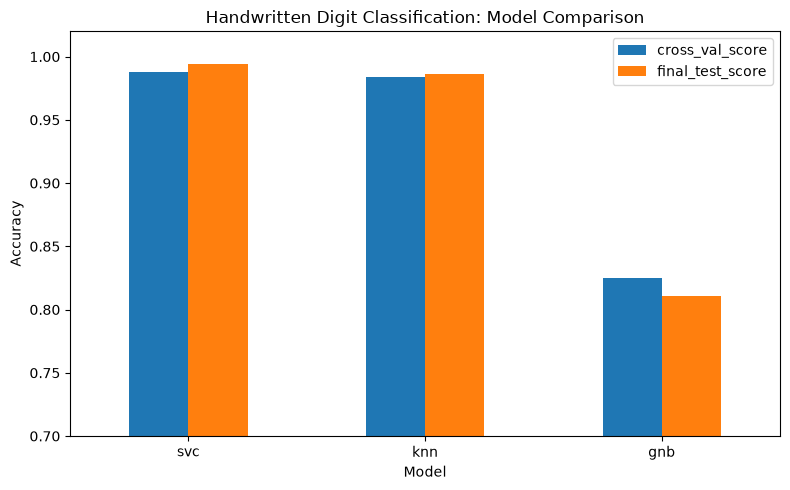

In [4]:
models_to_execute = {
    "knn": {"overrides": {"n_neighbors": [3, 5, 7]}, "data": None},
    "svc": {"overrides": {"C": [0.1, 1, 10], "gamma": ["scale", "auto"]}, "data": None},
    "gnb": {"overrides": None, "data": None}
}

for name, setup in models_to_execute.items():
    pipeline.run_generalized_pipeline(
        target_model_name=name,
        param_overrides=setup["overrides"],
        data_path_override=setup["data"]
    )

log_path = os.path.join(config["paths"]["log_dir"], "postal_results.csv")
results_df = pd.read_csv(log_path)

latest_uuids = results_df.groupby("engine_type")["run_uuid"].last()
latest_runs = (
    results_df[results_df["run_uuid"].isin(latest_uuids)]
    .groupby(["run_uuid", "engine_type", "test_mode"], as_index=False)[["mean_cv_accuracy", "final_test_score"]]
    .max()
)

leaderboard = latest_runs.sort_values(by="final_test_score", ascending=False).reset_index(drop=True)
display(leaderboard)

comparison_df = leaderboard.rename(columns={"mean_cv_accuracy": "cross_val_score"})
visualization.plot_model_comparison(comparison_df)

## 5. Make Predictions (10 points)

In [5]:
is_test = config.get("test_mode", False)
loaded_bundles = {}
predictions = {}

for _, row in latest_runs.iterrows():
    model_name = row["engine_type"]
    run_id = row["run_uuid"]
    bundle = utils.load_bundle(
        model_folder=config["paths"]["model_dir"],
        run_uuid=run_id,
        name=model_name,
        is_test=is_test
    )
    loaded_bundles[model_name] = bundle
    predictions[model_name] = bundle["model"].predict(X_test)
    print(f"{model_name.upper()} ({run_id}) sample predictions: {predictions[model_name][:10]}")

GNB (run_699576aa) sample predictions: [5 2 8 8 7 8 6 2 6 7]
SVC (run_8601dabb) sample predictions: [5 2 8 1 7 2 6 2 6 5]
KNN (run_df47a718) sample predictions: [5 2 8 1 7 2 6 2 6 5]


## 6. Evaluate the Result (10 points)

Winning Model: SVC
Best Hyperparameters: {'C': 10, 'gamma': 'scale'}

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      1.00      0.99        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       0.97      1.00      0.99        36
           8       1.00      0.97      0.99        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



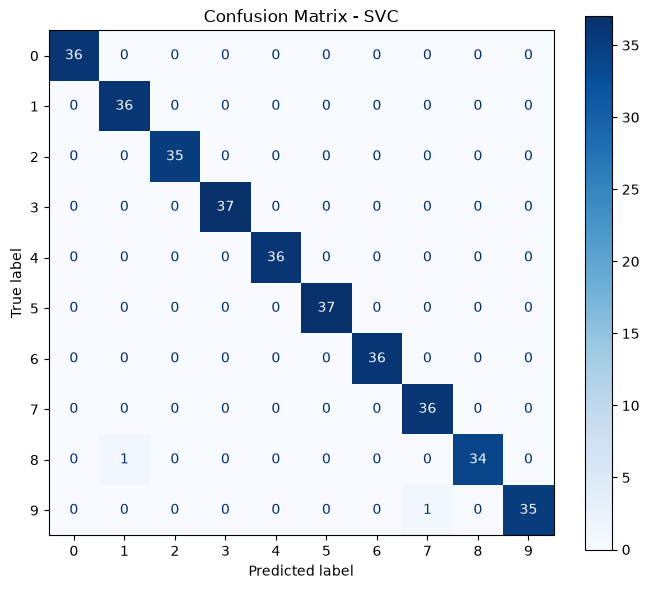

In [6]:
best_model_name = leaderboard.iloc[0]["engine_type"]
print(f"Winning Model: {best_model_name.upper()}")
print("Best Hyperparameters:", loaded_bundles[best_model_name]["metadata"]["best_tweaks"])
print("\nClassification Report:")
print(classification_report(y_test, predictions[best_model_name]))

visualization.plot_confusion_matrix(
    y_true=y_test,
    y_pred=predictions[best_model_name],
    title=f"Confusion Matrix - {best_model_name.upper()}"
)

## Conclusion

To classify handwritten digits across 1,797 pixel images (digits 0 through 9), three models were tested: **Support Vector Classifier (`SVC`)**, **K Nearest Neighbors (`KNeighborsClassifier`)**, and **Gaussian Naive Bayes (`GaussianNB`)**. The dataset was split into 1,437 training samples and 360 testing samples, using 5 fold cross validation to tune the models. All of the tuning runs, validation scores, and final test scores are saved in **`logs/postal_results.csv`**.

### Hyperparameter Tuning Selection
* **`SVC` (`C` and `gamma`):** `C` was tested across `0.1`, `1`, and `10` to control how strictly the model avoids misclassifying training points, while `gamma` compared `scale` and `auto` to adjust how far each training sample's influence reaches.
* **`KNeighborsClassifier` (`n_neighbors` and `weights`):** Odd neighbor counts (`3`, `5`, and `7`) were chosen to prevent tie votes among nearby digits, and `weights` compared equal voting (`uniform`) against proximity based voting (`distance`).
* **`GaussianNB` (Default Parameters):** No tuning grid was used since Naive Bayes computes probabilities directly from class averages and variances rather than iterative boundaries or neighbor counts.

### Key Findings
* **Highest Accuracy (`SVC`):** Reached **99.44%** accuracy on the test set (358 out of 360 images right) using `C=10` and `gamma="scale"`. It got every test image right for digits 0 through 7, with only 2 errors total (one `8` guessed as `1` and one `9` guessed as `7`).
* **Second Highest Accuracy (`KNeighborsClassifier`):** Reached **98.61%** accuracy on the test set using `weights="distance"`.
* **Lowest Accuracy (`GaussianNB`):** Reached **81.11%** accuracy on the test set with default settings.

### Model Selection
Based on both the cross validation results and the final test scores, the tuned **`SVC`** model (`artifacts/production/svc_8601dabb.pkl`) performed the best out of the three classifiers.

## Testing Custom Handwritten Digits

To test the winning **`SVC`** model on custom handwriting outside the benchmark dataset, four handwritten digits were photographed on paper, saved in the **`images/`** folder (`zero.jpg`, `three.jpg`, `four.jpg`, and `nine.jpg`), and processed using `utils.load_and_preprocess_images("images")`.

### Image Preprocessing (`src/utils.py`)
Because the model was trained on 8 by 8 grayscale images scaled from 0 (white) to 16 (black), raw photos from the **`images/`** folder are converted to match that format:
1. **Grayscale and Color Inversion:** Each photo is converted to grayscale and inverted so dark ink on light paper becomes bright values (16) on a dark background (0).
2. **Background Cleanup and Cropping:** Lighter paper pixels are cleared out, the bounding box around the remaining ink is found, and the cropped digit is centered inside a padded square frame.
3. **Stroke Thickening and Resizing:** The square image is resized to 64 by 64, thickened using `ImageFilter.MaxFilter(3)`, shrunk down to 8 by 8 pixels, and scaled from 0 to 16.

### Results (3 out of 4 Correct, 75% Accuracy)
* **Correct Predictions (3/4):** The `SVC` model correctly predicted **`zero.jpg` (0)**, **`three.jpg` (3)**, and **`nine.jpg` (9)**.
* **Incorrect Prediction (1/4):** The `SVC` model predicted **`four.jpg`** (True: 4) as **9**. In the 8 by 8 grid plot, the processed pixel pattern for `four.jpg` looks very similar to `nine.jpg`.
* **Benchmark Comparison:** On the `load_digits` test split (360 samples), the same `SVC` model reached **99.44%** accuracy, compared to **75.00%** (3 out of 4 samples) on the custom photographed digits.

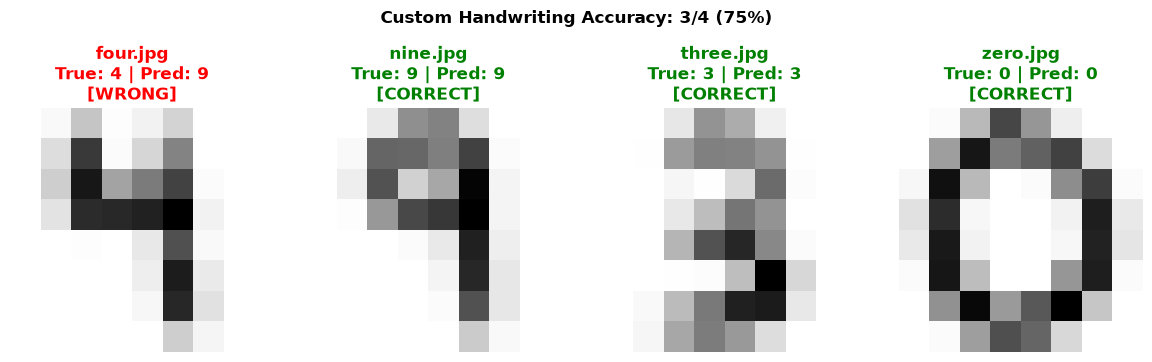

In [8]:
custom_X, custom_y, custom_names = utils.load_and_preprocess_images("images")
custom_preds = loaded_bundles["svc"]["model"].predict(custom_X)
visualization.plot_custom_predictions(custom_X, custom_y, custom_preds, custom_names)